# Sztuczna inteligencja: logika, przeszukiwanie, CSP
### Seminarium – przygotowanie do egzaminu

**Plan prezentacji**

1. Postaci normalne CNF i DNF, Skolemizacja
2. Równoważność zagadnień spełnialności i wynikania
3. Wnioskowanie w rachunku zdań: rezolucja, forward chaining, backward chaining
4. Algorytm A\* i heurystyki
5. Problemy spełniania więzów (CSP)

# 1. Postaci normalne CNF i DNF. Skolemizacja

## 1.1 Definicje – rachunek zdań

- **Literał** – zmienna zdaniowa (atom) $p$ albo jej negacja $\neg p$.
- **Klauzula** – alternatywa literałów: $l_1 \lor l_2 \lor \dots \lor l_k$.
- **CNF (koniunkcyjna postać normalna)** – koniunkcja klauzul:
$$\bigwedge_{i}\ \bigvee_{j}\ l_{ij} \qquad\text{np. } (p \lor \neg q) \land (q \lor r) \land \neg r$$
- **DNF (dysjunkcyjna postać normalna)** – alternatywa koniunkcji literałów:
$$\bigvee_{i}\ \bigwedge_{j}\ l_{ij} \qquad\text{np. } (p \land \neg q) \lor (q \land r) \lor \neg r$$

**Fakt.** Każda formuła rachunku zdań ma równoważną formułę w CNF i równoważną formułę w DNF.


## 1.2 Algorytm sprowadzania do CNF / DNF

1. Usuń równoważności: $\ A \Leftrightarrow B \ \equiv\ (A \Rightarrow B) \land (B \Rightarrow A)$
2. Usuń implikacje: $\ A \Rightarrow B \ \equiv\ \neg A \lor B$
3. Przesuń negacje do atomów (prawa De Morgana, $\neg\neg A \equiv A$)
4. Zastosuj rozdzielność:
   - dla **CNF** – $\lor$ względem $\land$: $\ A \lor (B \land C) \equiv (A \lor B) \land (A \lor C)$
   - dla **DNF** – $\land$ względem $\lor$: $\ A \land (B \lor C) \equiv (A \land B) \lor (A \land C)$


## 1.3 Przykład ręczny

$$\varphi = B \Leftrightarrow (P \lor Q)$$

| Krok | Wynik |
|---|---|
| 1. usunięcie $\Leftrightarrow$ | $(B \Rightarrow (P \lor Q)) \land ((P \lor Q) \Rightarrow B)$ |
| 2. usunięcie $\Rightarrow$ | $(\neg B \lor P \lor Q) \land (\neg(P \lor Q) \lor B)$ |
| 3. De Morgan (NNF) | $(\neg B \lor P \lor Q) \land ((\neg P \land \neg Q) \lor B)$ |
| 4. rozdzielność → **CNF** | $(\neg B \lor P \lor Q) \land (\neg P \lor B) \land (\neg Q \lor B)$ |

**DNF** (rozdzielność $\land$ względem $\lor$ w kroku 3 i usunięcie sprzecznych składników):
$$(B \land P) \lor (B \land Q) \lor (\neg B \land \neg P \land \neg Q)$$

## 1.4 Skolemizacja

**Na czym polega:** usuwamy każdy kwantyfikator $\exists$, zastępując jego zmienną *nowym* symbolem:

- $\exists x$ **poza** zasięgiem jakiegokolwiek $\forall$ → **stała Skolema**:
  $\ \exists x\, P(x) \ \leadsto\ P(c)$
- $\exists y$ **w zasięgu** $\forall x_1,\dots,\forall x_k$ → **funkcja Skolema** tych zmiennych:
  $\ \forall x\, \exists y\, Kocha(x,y) \ \leadsto\ \forall x\, Kocha(x, f(x))$

Funkcja jest konieczna, bo „świadek” $y$ może zależeć od $x$. Użycie stałej dałoby $\forall x\, Kocha(x,c)$ – „wszyscy kochają tę samą osobę” – czyli zdanie istotnie mocniejsze.

**Kluczowa własność:** formuła po Skolemizacji **nie jest równoważna** wyjściowej, ale jest z nią **równospełnialna** (spełnialna dokładnie wtedy, gdy oryginał).

**Dlaczego jest przydatna:**
- daje formułę bez kwantyfikatorów (same niejawne $\forall$) → zbiór klauzul, na którym działa **rezolucja z unifikacją**;
- dowodzenie przez zaprzeczenie bada tylko (nie)spełnialność $KB \land \neg\alpha$, więc równospełnialność w zupełności wystarcza;

### Przykład: „Każdego, kto kocha wszystkie zwierzęta, ktoś kocha”

$$\forall x\ [\forall y\ Zwierz(y) \Rightarrow Kocha(x,y)] \Rightarrow [\exists y\ Kocha(y,x)]$$

| Krok | Wynik |
|---|---|
| 1. usunięcie $\Rightarrow$ | $\forall x\ \neg[\forall y\ \neg Zwierz(y) \lor Kocha(x,y)] \lor [\exists y\ Kocha(y,x)]$ |
| 2. negacje do atomów | $\forall x\ [\exists y\ Zwierz(y) \land \neg Kocha(x,y)] \lor [\exists y\ Kocha(y,x)]$ |
| 3. standaryzacja zmiennych | $\forall x\ [\exists y\ Zwierz(y) \land \neg Kocha(x,y)] \lor [\exists z\ Kocha(z,x)]$ |
| 4. **Skolemizacja** | $\forall x\ [Zwierz(F(x)) \land \neg Kocha(x,F(x))] \lor Kocha(G(x),x)$ |
| 5. opuszczenie $\forall$ | $[Zwierz(F(x)) \land \neg Kocha(x,F(x))] \lor Kocha(G(x),x)$ |
| 6. rozdzielność → **CNF** | $[Zwierz(F(x)) \lor Kocha(G(x),x)] \land [\neg Kocha(x,F(x)) \lor Kocha(G(x),x)]$ |

$F(x)$ – „zwierzę, którego $x$ nie kocha”, $G(x)$ – „ktoś, kto kocha $x$”.

# 2. Spełnialność a wynikanie – równoważność zagadnień

## 2.1 Definicje

**KB** baza wiedzy (knowledge base) $\{P,\ P \Rightarrow Q\}$

| $\color{gray}{P}$ | $\color{gray}{Q}$ | $P$ | $P \Rightarrow Q$ |
|---|---|---|---|
| $\color{gray}{0}$ | $\color{gray}{0}$ | 0 | 1 |
| $\color{gray}{0}$ | $\color{gray}{1}$ | 0 | 1 |
| $\color{gray}{1}$ | $\color{gray}{0}$ | 1 | 0 |
| $\color{gray}{1}$ | $\color{gray}{1}$ | 1 | 1 |

**Model** to jeden wiersz tabeli. Dla zmiennych $P, Q$ są 4 możliwe modele:

| model | $\color{gray}{P}$ | $\color{gray}{Q}$ | model KB? |
|---|---|---|---|
| $M_1$ | $\color{gray}{0}$ | $\color{gray}{0}$ | nie |
| $M_2$ | $\color{gray}{0}$ | $\color{gray}{1}$ | nie |
| $M_3$ | $\color{gray}{1}$ | $\color{gray}{0}$ | nie |
| $M_4$ | $\color{gray}{1}$ | $\color{gray}{1}$ | **tak** ($M_4 \models KB$) |

**SAT** zbiór formuł jest spełnialny, jeśli istnieje choć jeden wiersz tabeli, w którym wszystkie formuły są prawdziwe.

| $\color{gray}{P}$ | $\color{gray}{Q}$ | $P$ | $P \Rightarrow Q$ | KB prawdziwe? |
|---|---|---|---|---|
| $\color{gray}{0}$ | $\color{gray}{0}$ | 0 | 1 | nie |
| $\color{gray}{0}$ | $\color{gray}{1}$ | 0 | 1 | nie |
| $\color{gray}{1}$ | $\color{gray}{0}$ | 1 | 0 | nie |
| $\color{gray}{1}$ | $\color{gray}{1}$ | 1 | 1 | **tak** ✓ |

**ENT** Wynikanie $KB \models \alpha$ zachodzi, gdy w każdym wierszu, w którym KB jest prawdziwe, α też jest prawdziwe.

| $\color{gray}{P}$ | $\color{gray}{Q}$ | $P$ | $P \Rightarrow Q$ | KB prawdziwe? | $\alpha = Q$ |
|---|---|---|---|---|---|
| $\color{gray}{0}$ | $\color{gray}{0}$ | 0 | 1 | nie | – |
| $\color{gray}{0}$ | $\color{gray}{1}$ | 0 | 1 | nie | – |
| $\color{gray}{1}$ | $\color{gray}{0}$ | 1 | 0 | nie | – |
| $\color{gray}{1}$ | $\color{gray}{1}$ | 1 | 1 | **tak** | **1** ✓ |

## 2.2 Twierdzenie (dowód przez zaprzeczenie)

$$\boxed{\,KB \models \alpha \iff KB \cup \{\neg\alpha\}\ \text{jest niespełnialny}\,}$$

**Dowód.**

($\Rightarrow$) Niech $KB \models \alpha$. Gdyby pewien model $M$ spełniał $KB \cup \{\neg\alpha\}$, to $M \models KB$, więc z założenia $M \models \alpha$; ale też $M \models \neg\alpha$ – sprzeczność. Zatem taki model nie istnieje.

($\Leftarrow$) Niech $KB \cup \{\neg\alpha\}$ będzie niespełnialny. Weźmy dowolny model $M \models KB$. Nie może zachodzić $M \models \neg\alpha$ (bo $M$ spełniałby cały zbiór), więc $M \models \alpha$. Zatem $KB \models \alpha$. $\blacksquare$

## 2.3 Redukcje w obie strony

### ENT → SAT (mamy algorytm `SAT`, chcemy rozstrzygać wynikanie)

```
ENT(KB, α):  not SAT(KB ∪ {¬α})
```

Pytanie: czy $KB \models Q$? Dopisujemy $\neg Q$ i sprawdzamy spełnialność $\{P,\ P \Rightarrow Q,\ \neg Q\}$:

| $P$ | $Q$ | $P$ | $P \Rightarrow Q$ | $\neg Q$ | wszystkie prawdziwe? |
|---|---|---|---|---|---|
| 0 | 0 | 0 | 1 | 1 | nie |
| 0 | 1 | 0 | 1 | 0 | nie |
| 1 | 0 | 1 | 0 | 1 | nie |
| 1 | 1 | 1 | 1 | 0 | nie |

Żaden wiersz nie spełnia zbioru, więc `SAT` = False, a zatem `ENT(KB, Q)` = **True**.

Kontrprzykład: czy $KB \models \neg Q$? Dopisujemy $\neg\neg Q \equiv Q$, czyli badamy $\{P,\ P \Rightarrow Q,\ Q\}$. Wiersz $P=1, Q=1$ spełnia wszystkie trzy formuły, więc `SAT` = True, a zatem `ENT(KB, ¬Q)` = **False**.

### SAT → ENT (mamy algorytm `ENT`, chcemy rozstrzygać spełnialność)

```
SAT(Γ):  not ENT(Γ, ⊥)
```
$\bot$ można wziąć $p \land \neg p$.

**(a)** $\Gamma = KB = \{P,\ P \Rightarrow Q\}$:

| $P$ | $Q$ | $P$ | $P \Rightarrow Q$ | model $\Gamma$? | $\bot$ |
|---|---|---|---|---|---|
| 0 | 0 | 0 | 1 | nie | 0 |
| 0 | 1 | 0 | 1 | nie | 0 |
| 1 | 0 | 1 | 0 | nie | 0 |
| 1 | 1 | 1 | 1 | **tak** | **0** |

W modelu $P=1, Q=1$ formuła $\bot$ jest fałszywa, więc $\Gamma \not\models \bot$. Zatem `ENT` = False, a `SAT(Γ)` = **True**.

**(b)** $\Gamma = \{P,\ P \Rightarrow Q,\ \neg Q\}$: z pierwszej tabeli wiemy, że zbiór nie ma żadnego modelu. Warunek „każdy model $\Gamma$ spełnia $\bot$” jest więc spełniony w pusty sposób, czyli $\Gamma \models \bot$. Zatem `ENT` = True, a `SAT(Γ)` = **False**.

### Wniosek

W obu kierunkach wystarczy **jedno wywołanie** drugiego algorytmu i **zanegowanie odpowiedzi**, a przekształcenie wejścia jest trywialne (dopisanie jednej formuły). Algorytm dla jednego zagadnienia natychmiast daje więc algorytm dla drugiego.

Pokrewne fakty: $KB \models \alpha \iff (KB \Rightarrow \alpha)$ jest tautologią (twierdzenie o dedukcji), a $\varphi$ jest tautologią $\iff \neg\varphi$ jest niespełnialna.

# 3. Wnioskowanie w rachunku zdań
### rezolucja · forward chaining · backward chaining

## 3.1 Rezolucja

**Reguła rezolucji** (dla klauzul):
$$\frac{A \lor l \qquad B \lor \neg l}{A \lor B}$$
Z dwóch klauzul zawierających przeciwne literały powstaje **rezolwenta**. Reguła jest *poprawna* (rezolwenta wynika z przesłanek).

**Algorytm (dowód przez zaprzeczenie):** aby sprawdzić $KB \models \alpha$:
1. sprowadź $KB \land \neg\alpha$ do CNF (zbiór klauzul);
2. dopóki się da, dodawaj rezolwenty par klauzul;
3. wyprowadzono **klauzulę pustą** $\square$ → sprzeczność → $KB \models \alpha$;
4. nie powstają już nowe klauzule → $KB \not\models \alpha$.

**Własności**
- **Refutacyjnie zupełna**: jeśli zbiór klauzul jest niespełnialny, to $\square$ da się wyprowadzić (tw. o rezolucji).
- Zawsze się zatrzymuje (skończenie wiele klauzul nad skończonym zbiorem zmiennych).
- Działa dla **dowolnych** formuł rachunku zdań.
- Koszt: w najgorszym razie **wykładnicza** liczba klauzul (czas i pamięć) – np. zasada szufladkowa wymaga dowodów rezolucyjnych wykładniczej długości (Haken, 1985). Zgodne z tym, że wynikanie jest co-NP-zupełne.

## 3.2 Klauzule Horna i wnioskowanie łańcuchowe

- **Klauzula Horna** – klauzula z **co najwyżej jednym** literałem pozytywnym.
$$\neg p_1 \lor \dots \lor \neg p_k \lor q \quad\equiv\quad p_1 \land \dots \land p_k \Rightarrow q$$

## 3.3 Forward chaining (wnioskowanie w przód)

**Idea – sterowanie danymi:** zaczynamy od znanych faktów i „odpalamy” każdą regułę, której wszystkie przesłanki są już znane, dopisując jej konkluzję; aż do wyprowadzenia zapytania lub braku nowych faktów.

- poprawny i zupełny dla klauzul określonych;
- wyprowadza **wszystkie** konsekwencje bazy – również nieistotne dla zapytania;
- naturalny, gdy napływają nowe fakty (systemy produkcyjne/reaktywne, monitorowanie, dedukcyjne bazy danych).

## 3.4 Backward chaining (wnioskowanie wstecz)

**Idea – sterowanie celem:** aby udowodnić $q$:
- jeśli $q$ jest faktem – sukces;
- w przeciwnym razie znajdź reguły o konkluzji $q$ i rekurencyjnie udowodnij **wszystkie** przesłanki którejś z nich.

Konieczne zabezpieczenia:
- **wykrywanie pętli** – nie dowodzimy celu, który już jest na stosie celów (np. $P \Rightarrow Q,\ Q \Rightarrow P$);
- **zapamiętywanie** celów już rozstrzygniętych – unikanie powtórnej pracy.

Własności:
- poprawny i zupełny dla klauzul określonych (z kontrolą pętli);
- czas w najgorszym razie liniowy (przy zapamiętywaniu), a w praktyce często **znacznie mniej niż liniowy** – dotyka tylko reguł istotnych dla zapytania;
- naturalny przy odpowiadaniu na konkretne pytania (diagnostyka, systemy ekspertowe); podstawa **Prologu**.

### Przykład:

$$P \Rightarrow Q,\quad L \land M \Rightarrow P,\quad B \land L \Rightarrow M,\quad A \land P \Rightarrow L,\quad A \land B \Rightarrow L,\quad A,\quad B \qquad\text{pytanie: } Q\,?$$

- **FC:** $A, B \to L \to M \to P \to Q$
- **BC:** $Q \leftarrow P \leftarrow (L, M)$; $\ L \leftarrow (A, P)$ – pętla na $P$, więc druga reguła: $L \leftarrow (A, B)$ ✓; $\ M \leftarrow (B, L)$ ✓

- **Rezolucja:** 

| krok | klauzule | wykreślam | rezolwenta |
|---|---|---|---|
| 1 | $\neg Q$, $\ \neg P \lor Q$ | $Q$ | $\neg P$ |
| 2 | $\neg P$, $\ \neg L \lor \neg M \lor P$ | $P$ | $\neg L \lor \neg M$ |
| 3 | $A$, $\ \neg A \lor \neg B \lor L$ | $A$ | $\neg B \lor L$ |
| 4 | $B$, $\ \neg B \lor L$ | $B$ | $L$ |
| 5 | $L$, $\ \neg L \lor \neg M$ | $L$ | $\neg M$ |
| 6 | $B$, $\ \neg B \lor \neg L \lor M$ | $B$ | $\neg L \lor M$ |
| 7 | $L$, $\ \neg L \lor M$ | $L$ | $M$ |
| 8 | $M$, $\ \neg M$ | $M$ | $\square$ – sprzeczność, więc $KB \models Q$ ✓ |

## 3.5 Porównanie

| | **Rezolucja** | **Forward chaining** | **Backward chaining** |
|---|---|---|---|
| Zakres | dowolne formuły (po konwersji do CNF) | tylko klauzule Horna (określone) | tylko klauzule Horna (określone) |
| Poprawność / zupełność | poprawna, refutacyjnie zupełna | poprawny, zupełny dla Horna | poprawny, zupełny dla Horna (z kontrolą pętli) |
| Złożoność | wykładnicza w najgorszym razie (problem co-NP-zupełny) | liniowa względem rozmiaru bazy | liniowa w najgorszym razie, często podliniowa |
| Sterowanie | brak naturalnego kierunku (dowód nie wprost) | danymi – od faktów | celem – od zapytania |
| Zalety | pełna siła wyrazu, jedna reguła wnioskowania | prosty, wylicza wszystkie konsekwencje, dobry przy napływie nowych faktów | pracuje tylko nad tym, co istotne dla pytania |
| Wady | eksplozja liczby klauzul, duża pamięć | wyprowadza też fakty nieistotne | pętle i powtarzane podcele bez dodatkowych zabezpieczeń |
| Zastosowania | dowodzenie twierdzeń, weryfikacja (dziś zwykle solvery SAT) | systemy regułowe/produkcyjne, Datalog | Prolog, systemy ekspertowe, diagnostyka |

# 4. Algorytm A\* i heurystyki

## 4.1 Algorytm

A\* to przeszukiwanie **best-first** z funkcją oceny węzła
$$f(n) = g(n) + h(n)$$

- $g(n)$ – koszt najlepszej znanej ścieżki od startu do $n$,
- $h(n)$ – **heurystyka**: oszacowanie kosztu najtańszej ścieżki z $n$ do celu,
- $f(n)$ – oszacowanie kosztu najtańszego rozwiązania przechodzącego przez $n$.




Przypadki szczególne: $h \equiv 0$ → algorytm **Dijkstry** (uniform-cost search); $f = h$ → zachłanne best-first (szybkie, nieoptymalne).

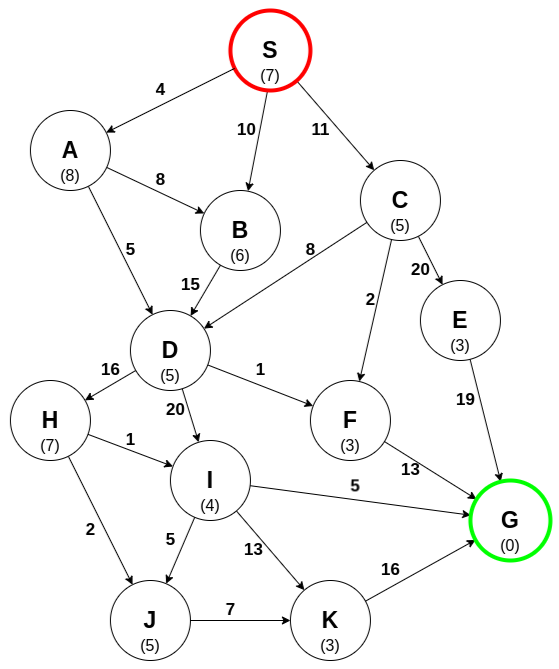

## 4.2 Rola heurystyki i jej pożądane własności

Heurystyka wnosi **wiedzę o problemie**: kieruje przeszukiwanie w stronę celu, dzięki czemu A\* rozwija znacznie mniej węzłów niż przeszukiwanie ślepe.

**Dopuszczalność (admissibility)** – heurystyka nigdy nie przeszacowuje:
$$\forall n:\quad 0 \le h(n) \le h^*(n) \qquad (h^* \text{ – rzeczywisty koszt optymalny do celu})$$

**Monotoniczność / spójność** – nierówność trójkąta:
$$\forall n, n':\quad h(n) \le c(n, n') + h(n'), \qquad h(\text{cel}) = 0$$

- spójna ⟹ dopuszczalna (odwrotnie – niekoniecznie);
- przy spójnej $h$ wartości $f$ wzdłuż każdej ścieżki **nie maleją**, więc węzeł w chwili rozwinięcia ma już optymalne $g$ – nie trzeba go ponownie otwierać.

**Gwarancje optymalności**

| heurystyka | wersja drzewiasta / z ponownym otwieraniem węzłów | wersja grafowa bez ponownego otwierania |
|---|---|---|
| dopuszczalna | optymalny | **może zwrócić rozwiązanie nieoptymalne** |
| spójna | optymalny | optymalny |

# 5. Problemy spełniania więzów (CSP)

## 5.1 Definicja

Problem spełniania więzów to trójka $(X, D, C)$:

- $X = \{X_1, \dots, X_n\}$ – **zmienne**,
- $D = \{D_1, \dots, D_n\}$ – **dziedziny** (zbiory dopuszczalnych wartości zmiennych),
- $C$ – **więzy (ograniczenia)**: każdy więz dotyczy pewnego podzbioru zmiennych i określa dozwolone kombinacje ich wartości.

**Rozwiązanie** = przypisanie **zupełne** (każda zmienna ma wartość) i **spójne** (żaden więz nie jest naruszony).

## 5.2 Przykłady

| Problem | Zmienne | Dziedziny | Więzy |
|---|---|---|---|
| **Kolorowanie mapy / grafu** | regiony | kolory | sąsiednie regiony mają różne kolory |
| **$n$ hetmanów** | kolumny szachownicy | numer wiersza hetmana | brak wspólnego wiersza i przekątnej |
| **Sudoku** | 81 pól | cyfry 1–9 | *AllDiff* w wierszach, kolumnach i blokach |
| **Układanie planu zajęć** | zajęcia | (termin, sala) | brak kolizji sal, prowadzących i grup |

## 5.3 Backtracking (przeszukiwanie z nawrotami)

Przeszukiwanie w głąb, w którym:
- w każdym węźle przypisujemy wartość **jednej** zmiennej (przypisania są przemienne – kolejność nie ma znaczenia, więc nie rozważamy permutacji),
- po każdym przypisaniu sprawdzamy więzy; naruszenie → natychmiastowy **nawrót**.

Algorytm **zupełny** (znajdzie rozwiązanie lub wykaże jego brak), pamięć liniowa, czas w najgorszym razie $O(d^n)$.

## 5.4 Usprawnienia backtrackingu

**1. Którą zmienną wybrać?**
- **MRV** (minimum remaining values, „fail-first”) – zmienna o najmniejszej liczbie pozostałych wartości;
- **heurystyka stopnia** – przy remisie zmienna uwikłana w najwięcej więzów z nieprzypisanymi.

**2. Którą wartość wypróbować najpierw?**
- **LCV** (least constraining value) – wartość wykluczająca najmniej możliwości u sąsiadów.

**3. Wnioskowanie – wczesne wykrywanie porażek (propagacja więzów)**
- **Forward checking** – po przypisaniu $X = v$ usuń niezgodne wartości z dziedzin nieprzypisanych sąsiadów; pusta dziedzina → nawrót.

## 5.5 Przeszukiwanie lokalne: min-conflicts

Inne podejście: pracujemy na przypisaniach **zupełnych** (zwykle niespójnych) i je **naprawiamy**.

- Bardzo skuteczne dla dużych problemów z gęsto rozłożonymi rozwiązaniami: $n$ hetmanów dla $n$ rzędu milionów w średnio kilkudziesięciu krokach; planowanie obserwacji teleskopu Hubble'a.
- Stała pamięć; dobrze nadaje się do **naprawy online** (zmiana w planie → mała korekta zamiast liczenia od zera).
- **Niezupełne**: nie potrafi wykazać braku rozwiązania; może utknąć w minimum lokalnym

### Eksperyment: problem $n$ hetmanów – porównanie algorytmów

Miara dla backtrackingu: liczba prób przypisania wartości; dla min-conflicts: liczba kroków naprawy.

  n |              BT |         BT + FC |   BT + FC + MRV | min-conflicts
  8 |             876 |              88 |              75 |           140
 12 |            3066 |             193 |             153 |           208
 16 |          160712 |            7560 |              44 |            27
 20 |         3992510 |          145151 |             145 |           139


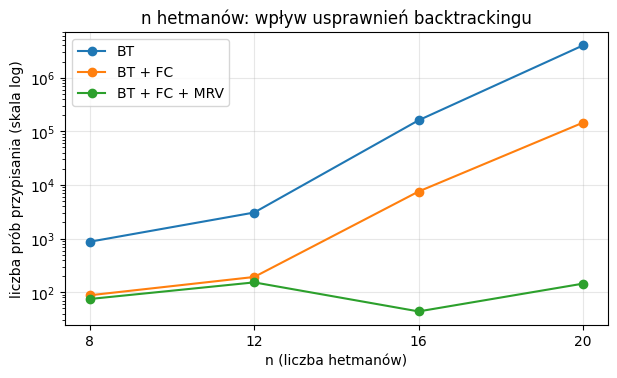

In [31]:
konfiguracje = [('BT', {}),
                ('BT + FC', {'wnioskowanie': 'fc'}),
                ('BT + FC + MRV', {'wnioskowanie': 'fc', 'mrv': True})]

rozmiary = [8, 12, 16, 20]
wyniki = {nazwa: [] for nazwa, _ in konfiguracje}

print(f"{'n':>3} | " + ' | '.join(f'{nazwa:>15}' for nazwa, _ in konfiguracje) + f" | {'min-conflicts':>13}")
for n in rozmiary:
    wiersz = []
    for nazwa, opcje in konfiguracje:
        _, stat = backtracking(hetmani(n), **opcje)
        wyniki[nazwa].append(stat['przypisania']); wiersz.append(stat['przypisania'])
    _, kroki = min_conflicts(hetmani(n))
    print(f'{n:>3} | ' + ' | '.join(f'{w:>15}' for w in wiersz) + f' | {kroki:>13}')

plt.figure(figsize=(7, 3.8))
for nazwa, _ in konfiguracje:
    plt.plot(rozmiary, wyniki[nazwa], marker='o', label=nazwa)
plt.yscale('log'); plt.xticks(rozmiary)
plt.xlabel('n (liczba hetmanów)'); plt.ylabel('liczba prób przypisania (skala log)')
plt.title('n hetmanów: wpływ usprawnień backtrackingu'); plt.legend(); plt.grid(alpha=0.3); plt.show()

   n | kroki naprawy | czas [s]
  20 |           139 |     0.04
  50 |            49 |     0.11
 100 |            31 |     0.48
 200 |            87 |     4.32


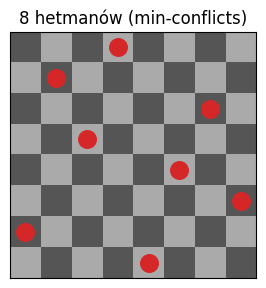

In [ ]:

print(f"{'n':>4} | {'kroki naprawy':>13} | {'czas [s]':>8}")
for n in [20, 50, 100, 200]:
    t = time.perf_counter()
    rozw, kroki = min_conflicts(hetmani(n))
    print(f'{n:>4} | {kroki:>13} | {time.perf_counter() - t:>8.2f}')

# Rozwiązanie dla n = 8
rozw, _ = min_conflicts(hetmani(8))
fig, os_ = plt.subplots(figsize=(3.2, 3.2))
os_.imshow([[(r + c) % 2 for c in range(8)] for r in range(8)], cmap='gray', vmin=-1, vmax=2)
os_.scatter(list(rozw.keys()), list(rozw.values()), s=160, color='tab:red', marker='o')
os_.set_xticks([]); os_.set_yticks([]); os_.set_title('8 hetmanów (min-conflicts)'); plt.show()

+## 5.6 Porównanie algorytmów CSP

| | **Backtracking** | **BT + heurystyki + propagacja** | **Przeszukiwanie lokalne (min-conflicts)** |
|---|---|---|---|
| Stan | przypisanie częściowe, spójne | przypisanie częściowe + przycięte dziedziny | przypisanie zupełne, zwykle niespójne |
| Zupełność | tak | tak | **nie** – nie wykaże braku rozwiązania |
| Czas | $O(d^n)$ | $O(d^n)$ w najgorszym razie, w praktyce o rzędy wielkości mniej | brak gwarancji; często bardzo szybkie |
| Pamięć | liniowa | liniowa (+ dziedziny) | stała |
| Koszt jednego kroku | niski | wyższy (FC < MAC) – opłaca się przy trudnych instancjach | niski |
| Mocne strony | prostota, wszystkie rozwiązania, dowód sprzeczności | trudne, mocno ograniczone problemy (Sudoku, planowanie) | bardzo duże problemy z wieloma rozwiązaniami, naprawa online |
| Słabości | *thrashing* – wielokrotne odkrywanie tej samej porażki | narzut propagacji przy łatwych instancjach | minima lokalne, plateau; słabe przy nielicznych rozwiązaniach |